In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Making sure all columns show
import pandas as pd, numpy as np
df = pd.read_csv("adult.csv")
print(df.shape)
df.info()
df.describe(include='all')

(32561, 15)
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
count,32561.000000,32561,3.256100e+04,32561,32561.000000,32561,32561,32561,32561,32561,32561.000000,32561.000000,32561.000000,32561,32561
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [3]:
# For some reason this dataset has missing values as ?, so we're replacing them with NAN.
df = df.replace("?", np.nan)
# strip whitespace from all text columns
for c in df.select_dtypes(include=['object', 'str']).columns:
    df[c] = df[c].str.strip()

In [4]:
# Drop all missing values
df = df.dropna()

In [5]:
# Remove duplicates
df = df.drop_duplicates()

In [6]:
# Dropping Education since education.num is essentially an encoded numeric representation that's easier to work with. Here is the matching:
'''
Preschool	1
1st-4th	2
5th-6th	3
7th-8th	4
9th	5
10th	6
11th	7
12th	8
HS-grad	9
Some-college	10
Assoc-voc	11
Assoc-acdm	12
Bachelors	13
Masters	14
Prof-school	15
Doctorate	16
'''
# Also dropping fnlwgt since its just a sampling weight
df = df.drop(columns=['education', 'fnlwgt'])

In [7]:
# Encoding income to be binary, 0 if less than 50k, 1 if more.
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

In [8]:
# Turning native country into either US or Other, since its 90% U.S
df['native.country'] = np.where(df['native.country']=='United-States', 'US', 'Other')

In [9]:
# Turning all the string values into binary values.
df = pd.get_dummies(df, columns=['workclass','marital.status','occupation',
                                 'relationship','race','sex','native.country'],
                    drop_first=True)

In [10]:
# Split dataset for training into 80/20 data,
from sklearn.model_selection import train_test_split
X = df.drop(columns=['income'])
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [11]:
# Scale numeric features and fit the scaler on the training data
from sklearn.preprocessing import StandardScaler
num_cols = ['age','education.num','capital.gain','capital.loss','hours.per.week']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

In [12]:
# Just making sure everything is good lol
print(X_train.isna().sum().sum(), "missing in train") 
print(X_train.dtypes.value_counts())
print(X_train.shape, X_test.shape)

0 missing in train
bool       36
float64     5
Name: count, dtype: int64
(24111, 41) (6028, 41)


# Model 1: Ensemble Learning with Decision Trees

In [22]:
# Exploring what the data actually looks like right now
df.describe(include='all')
pd.set_option('display.max_columns', None)
df.head()

,age,education.num,capital.gain,capital.loss,hours.per.week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital.status_Married-AF-spouse,marital.status_Married-civ-spouse,marital.status_Married-spouse-absent,marital.status_Never-married,marital.status_Separated,marital.status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native.country_US
1,82,9,0,4356,18,0,False,True,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,True
3,54,4,0,3900,40,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True
4,41,10,0,3900,40,0,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,True,False,True
5,34,9,0,3770,45,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True
6,38,6,0,3770,40,0,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,True,True


In [23]:
print(df.shape[0])

30139


In [34]:
print(y_test[y_test== 1].count())

1501


In [14]:
# Looking at the distribution of classes
for col in df:
    print(df[col].value_counts(), "\n")

age
36    852
31    851
33    837
34    836
37    828
     ... 
82      7
83      5
88      3
85      3
86      1
Name: count, Length: 72, dtype: int64 

education.num
9     9834
10    6669
13    5042
14    1626
11    1307
7     1048
12    1008
6      820
4      556
15     542
5      455
8      377
16     375
3      287
2      149
1       44
Name: count, dtype: int64 

capital.gain
0        27601
15024      337
7688       270
7298       240
99999      148
         ...  
1639         1
1455         1
1173         1
1086         1
401          1
Name: count, Length: 118, dtype: int64 

capital.loss
0       28712
1902      194
1977      162
1887      155
1848       50
        ...  
1844        1
1539        1
1411        1
419         1
155         1
Name: count, Length: 90, dtype: int64 

hours.per.week
40    14239
50     2716
45     1752
60     1405
35     1183
      ...  
87        1
94        1
82        1
92        1
74        1
Name: count, Length: 94, dtype: int64 

income
0    226

In [44]:
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [45]:
clf = tree.DecisionTreeClassifier()
clf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.63      0.63      1501

    accuracy                           0.82      6028
   macro avg       0.75      0.76      0.75      6028
weighted avg       0.82      0.82      0.82      6028



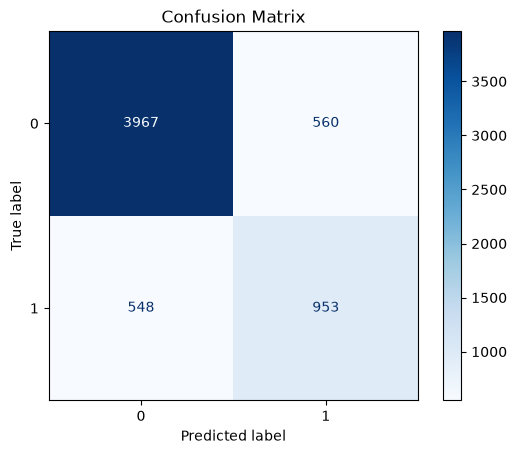

In [48]:
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues) 
plt.title("Confusion Matrix")
plt.show() 

In [49]:
def predict_on_subset(col, val, model):
    df_subset = df[df[col] == val]
    X_subset = df_subset.drop(columns=['income'])
    y_subset = df_subset['income']
    X_train_subset, X_test_subset, y_train_subset, y_test_subset = train_test_split(
        X_subset, y_subset, test_size=0.2, random_state=42, stratify=y_subset)
    y_pred_subset = model.predict(X_test_subset)
    cm = confusion_matrix(y_test_subset, y_pred_subset)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues) 
    print(classification_report(y_test, y_pred))
    plt.title("Confusion Matrix")
    plt.show() 


              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.63      0.63      1501

    accuracy                           0.82      6028
   macro avg       0.75      0.76      0.75      6028
weighted avg       0.82      0.82      0.82      6028



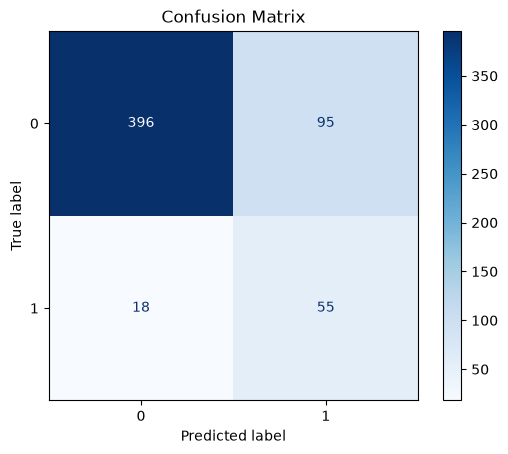

In [50]:
predict_on_subset('race_Black', True, clf)

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.63      0.63      1501

    accuracy                           0.82      6028
   macro avg       0.75      0.76      0.75      6028
weighted avg       0.82      0.82      0.82      6028



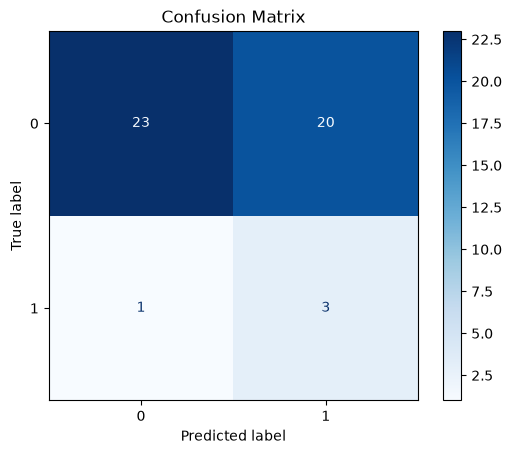

In [51]:
predict_on_subset('race_Other', True, clf)

In [56]:
def test_model(clf):
    y_pred = clf.predict(X_test)
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues) 
    plt.title("Confusion Matrix")
    plt.show() 

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



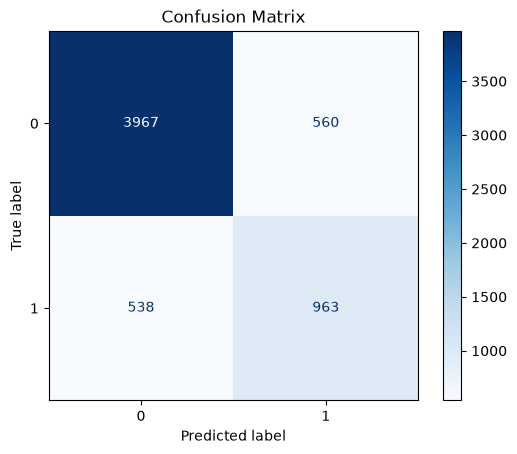

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



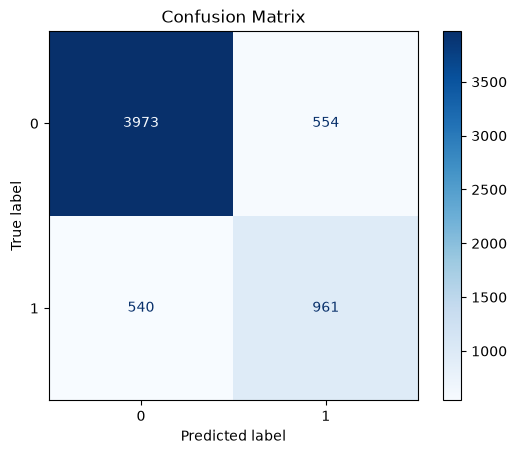

In [58]:
clf = tree.DecisionTreeClassifier(criterion='entropy')
clf.fit(X_train, y_train)
test_model(clf)
clf = tree.DecisionTreeClassifier(criterion='gini')
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.86      0.96      0.90      4527
           1       0.80      0.52      0.63      1501

    accuracy                           0.85      6028
   macro avg       0.83      0.74      0.77      6028
weighted avg       0.84      0.85      0.84      6028



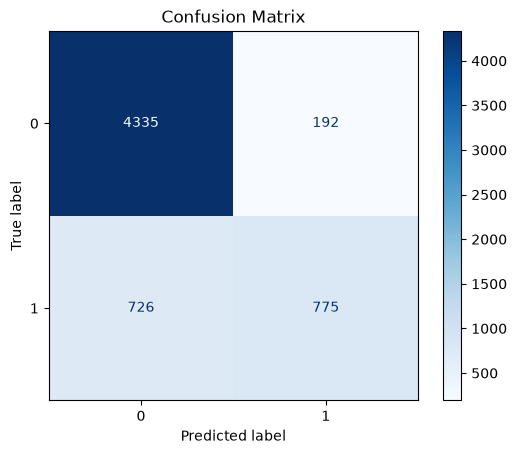

In [59]:
clf = tree.DecisionTreeClassifier(max_depth=5)
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.89      0.90      0.90      4527
           1       0.69      0.67      0.68      1501

    accuracy                           0.84      6028
   macro avg       0.79      0.79      0.79      6028
weighted avg       0.84      0.84      0.84      6028



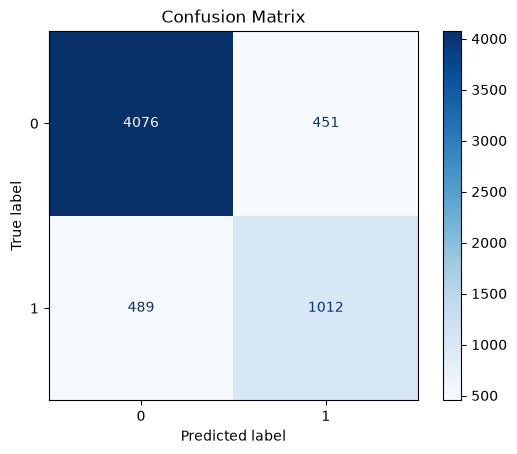

In [60]:
clf = tree.DecisionTreeClassifier(max_depth=15)
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.89      0.92      0.90      4527
           1       0.72      0.67      0.70      1501

    accuracy                           0.85      6028
   macro avg       0.81      0.79      0.80      6028
weighted avg       0.85      0.85      0.85      6028



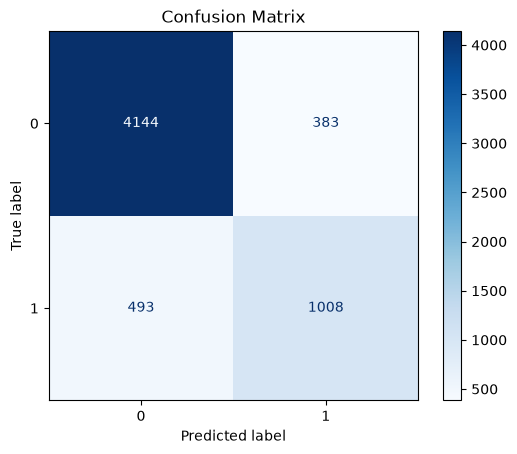

              precision    recall  f1-score   support

           0       0.89      0.89      0.89      4527
           1       0.66      0.66      0.66      1501

    accuracy                           0.83      6028
   macro avg       0.77      0.77      0.77      6028
weighted avg       0.83      0.83      0.83      6028



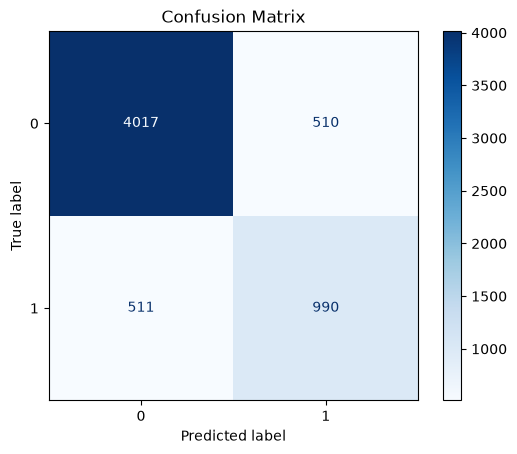

In [67]:
clf = tree.DecisionTreeClassifier(max_depth=10)
clf.fit(X_train, y_train)
test_model(clf)
clf = tree.DecisionTreeClassifier(max_depth=20)
clf.fit(X_train, y_train)
test_model(clf)

It looks like a decision tree with a maximum depth of 15 works the best with the highest f1 score and achieves the best fit for correctly identifying actual positive cases

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



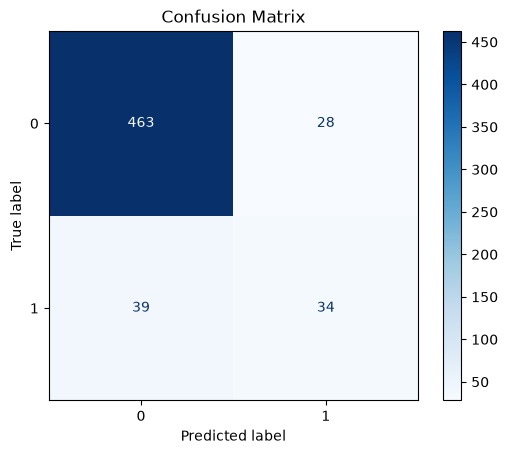

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



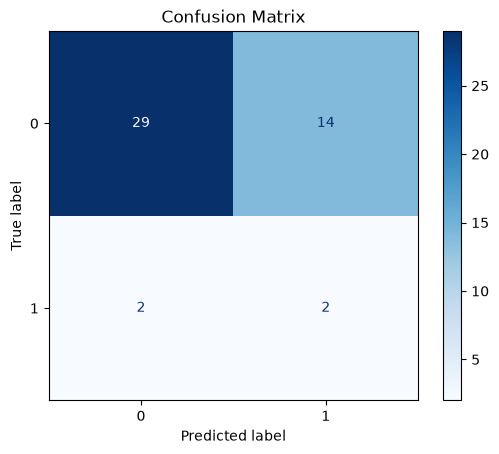

In [70]:
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

However, the limited depth is making it less prone to correctly predicting high income black earners which is problematic. I am going to try bagging next to see if it can provide a better fit

In [71]:
from sklearn.ensemble import BaggingClassifier

              precision    recall  f1-score   support

           0       0.89      0.94      0.91      4527
           1       0.77      0.66      0.71      1501

    accuracy                           0.87      6028
   macro avg       0.83      0.80      0.81      6028
weighted avg       0.86      0.87      0.86      6028



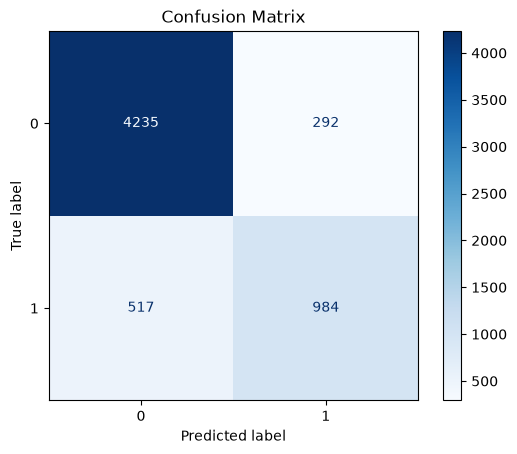

In [76]:
base_tree = tree.DecisionTreeClassifier(max_depth=15)
bagging_clf = bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



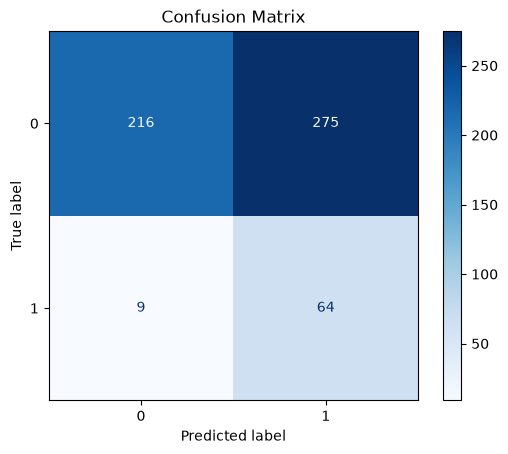

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



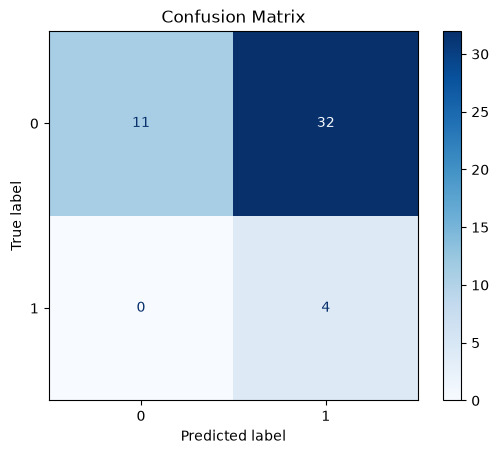

In [77]:
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

              precision    recall  f1-score   support

           0       0.89      0.91      0.90      4527
           1       0.71      0.65      0.68      1501

    accuracy                           0.85      6028
   macro avg       0.80      0.78      0.79      6028
weighted avg       0.84      0.85      0.84      6028



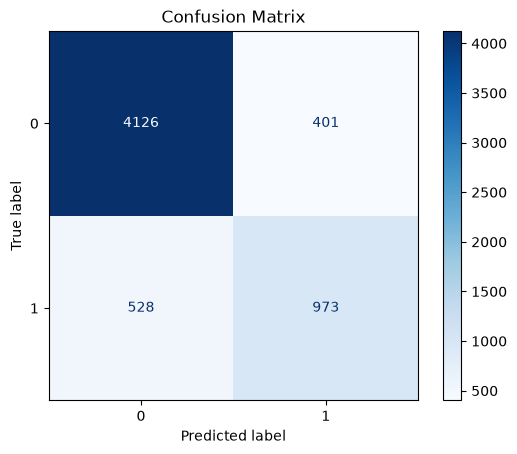

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



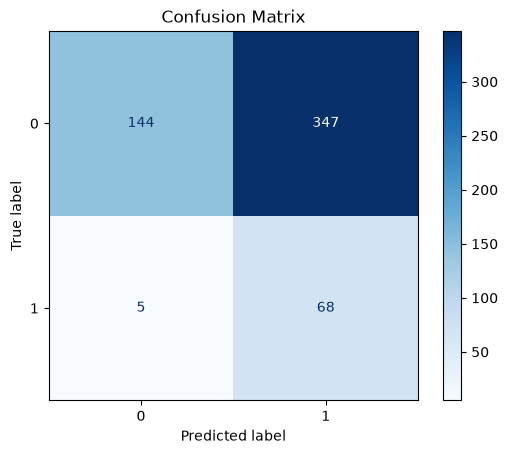

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



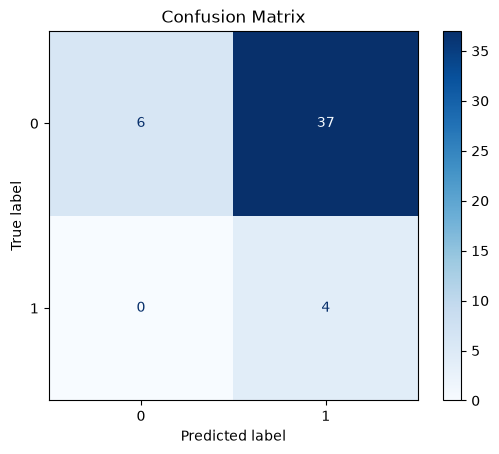

In [78]:
base_tree = tree.DecisionTreeClassifier(max_depth=50)
bagging_clf = bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

### Trying with class weights balanced

              precision    recall  f1-score   support

           0       0.94      0.79      0.86      4527
           1       0.57      0.84      0.68      1501

    accuracy                           0.80      6028
   macro avg       0.76      0.82      0.77      6028
weighted avg       0.85      0.80      0.82      6028



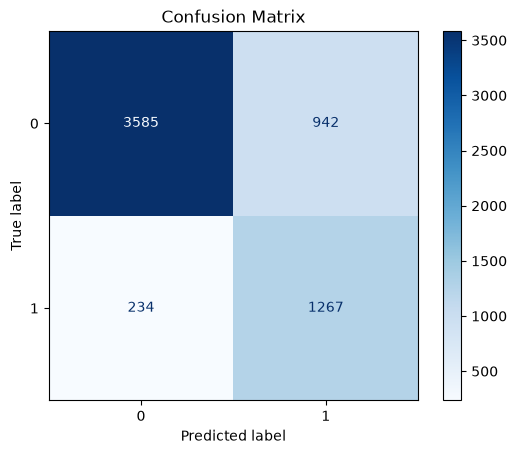

In [80]:
clf = tree.DecisionTreeClassifier(max_depth=15, class_weight='balanced')
clf.fit(X_train, y_train)
test_model(clf)

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



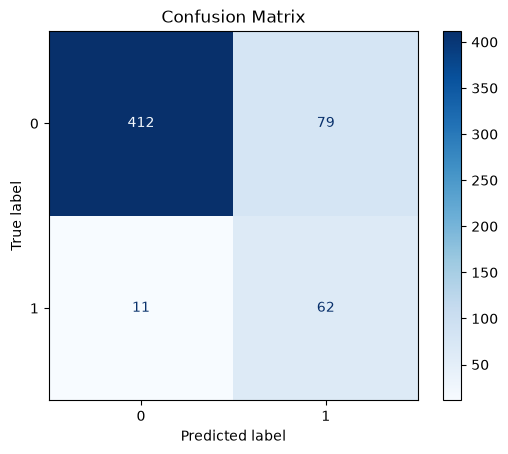

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



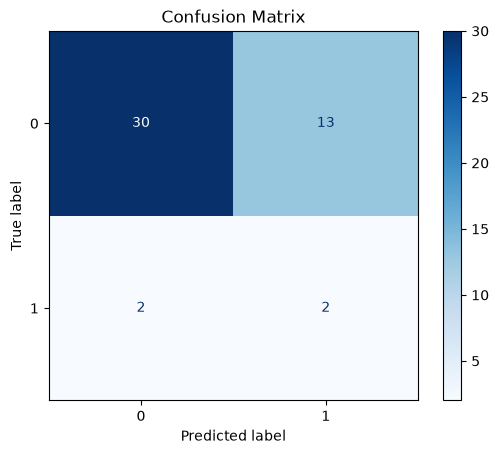

In [82]:
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

Balancing the class weights did a really good job at mitigating the racial bias within the model, but it did result in lower overall accuracy. I am going to try increasing the depth to see if that can help

              precision    recall  f1-score   support

           0       0.93      0.81      0.87      4527
           1       0.59      0.83      0.69      1501

    accuracy                           0.81      6028
   macro avg       0.76      0.82      0.78      6028
weighted avg       0.85      0.81      0.82      6028



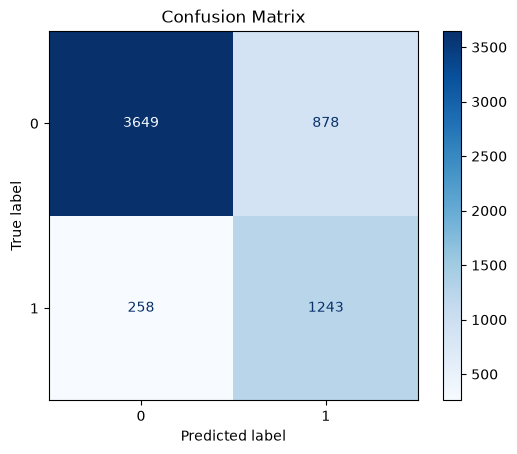

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



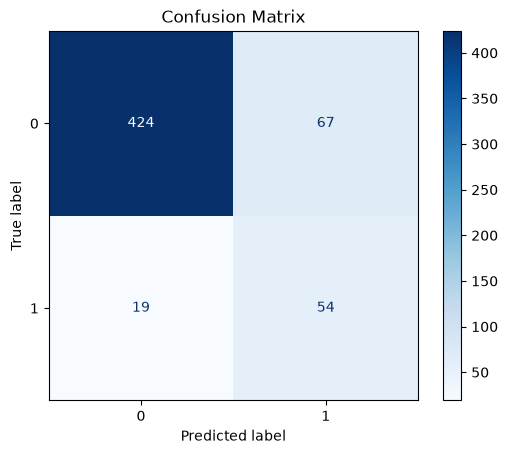

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



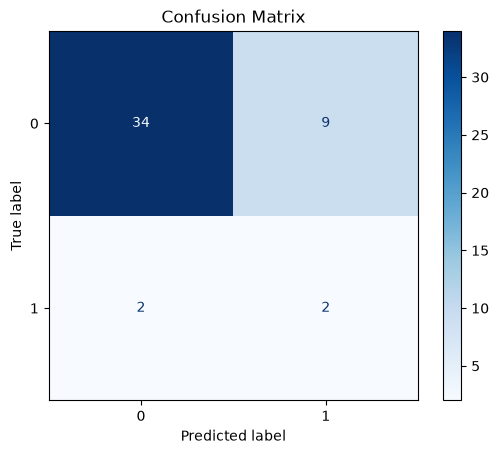

In [94]:
clf = tree.DecisionTreeClassifier(max_depth=20, class_weight='balanced')
clf.fit(X_train, y_train)
test_model(clf)
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

20 seems like a better depth now with a 0.87 F1 score compared to the previous 0.86 and only a minor decrease in accuracy for black earners. A depth of 15 still makes more sense if focusing on eliminating racial bias though.

              precision    recall  f1-score   support

           0       0.94      0.83      0.88      4527
           1       0.62      0.83      0.71      1501

    accuracy                           0.83      6028
   macro avg       0.78      0.83      0.80      6028
weighted avg       0.86      0.83      0.84      6028



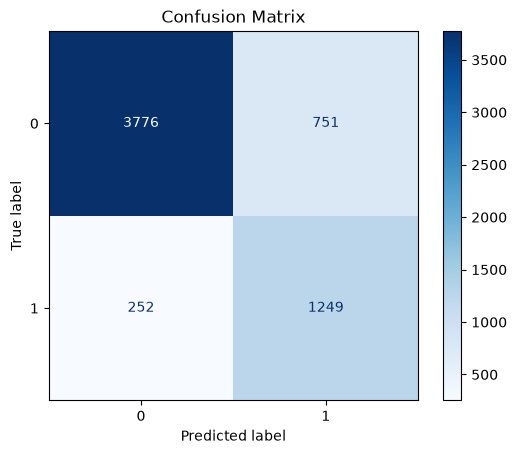

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



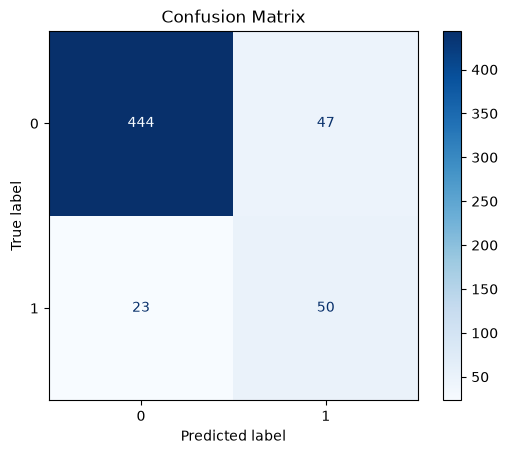

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



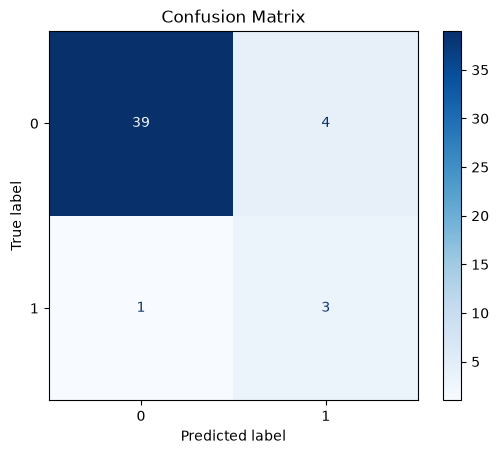

In [95]:
base_tree = tree.DecisionTreeClassifier(max_depth=15, class_weight='balanced')
bagging_clf = bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

This led to a significant number of false positives

## Trying to change min_samples_split

              precision    recall  f1-score   support

           0       0.94      0.79      0.86      4527
           1       0.57      0.84      0.68      1501

    accuracy                           0.80      6028
   macro avg       0.75      0.82      0.77      6028
weighted avg       0.85      0.80      0.81      6028



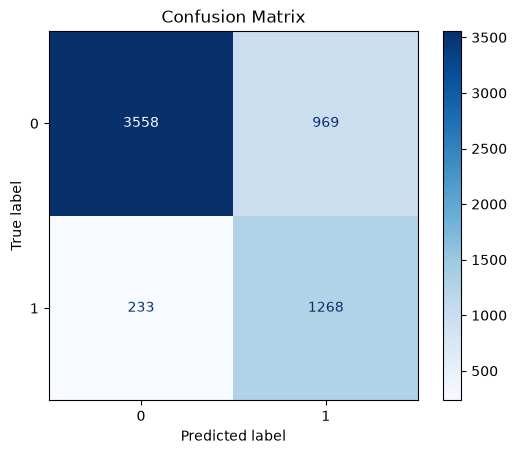

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



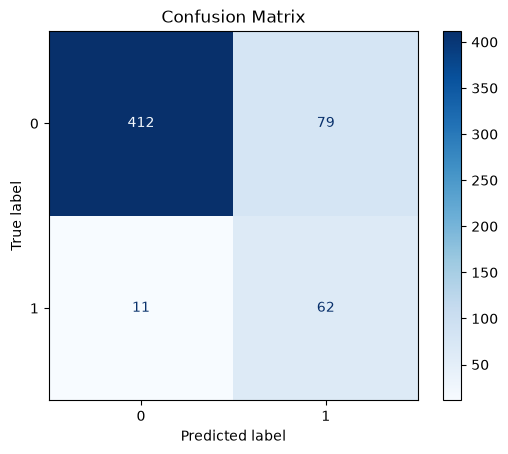

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



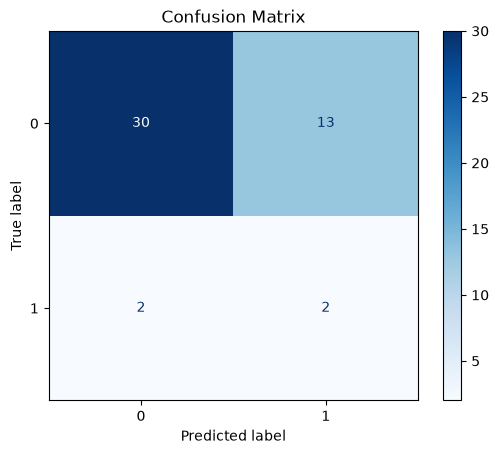

In [98]:
clf = tree.DecisionTreeClassifier(max_depth=15, class_weight='balanced')
clf.fit(X_train, y_train)
test_model(clf)
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

worsens false positives

## Attempting a Stacking Approach

In [102]:
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [105]:
estimators = [
    ('random_forest', RandomForestClassifier(n_estimators=10, random_state=42)),
    ('decision_tree', DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=42))
]
stacking_clf = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression())
stacking_clf.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('random_forest', ...), ('decision_tree', ...)]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegression()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[RandomForestC...ndom_state=42), DecisionTreeC...ndom_state=42)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[objec

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      4527
           1       0.71      0.64      0.67      1501

    accuracy                           0.85      6028
   macro avg       0.80      0.78      0.79      6028
weighted avg       0.84      0.85      0.84      6028



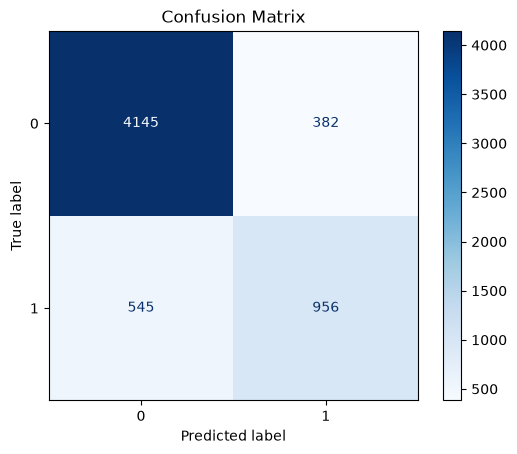

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



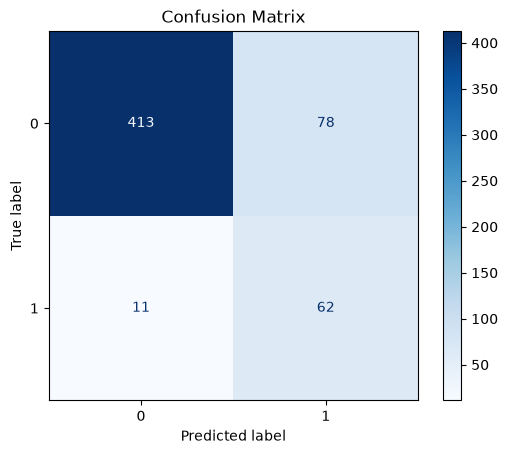

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



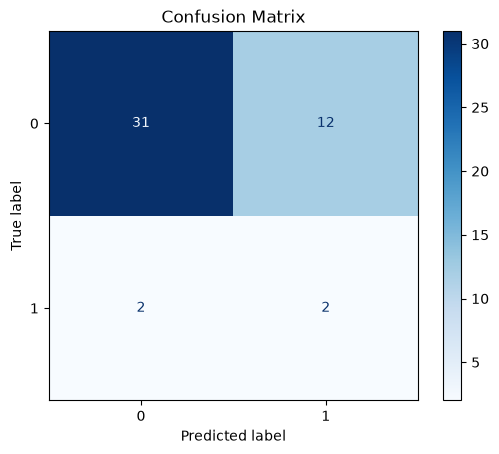

In [106]:
test_model(stacking_clf)
predict_on_subset('race_Black', True, stacking_clf)
predict_on_subset('race_Other', True, stacking_clf)

Using stacking led to a higher f1 score with more false negatives. Interestingly, false positives are now over represented in racial minorities while false negatives are significantly lower. False postives from black individuals make up almost 20% of the false positives even though black individuals only make up around 10% of the data's population

### Trying bagging the stacked algorithm, just because

              precision    recall  f1-score   support

           0       0.89      0.93      0.91      4527
           1       0.75      0.65      0.70      1501

    accuracy                           0.86      6028
   macro avg       0.82      0.79      0.80      6028
weighted avg       0.85      0.86      0.86      6028



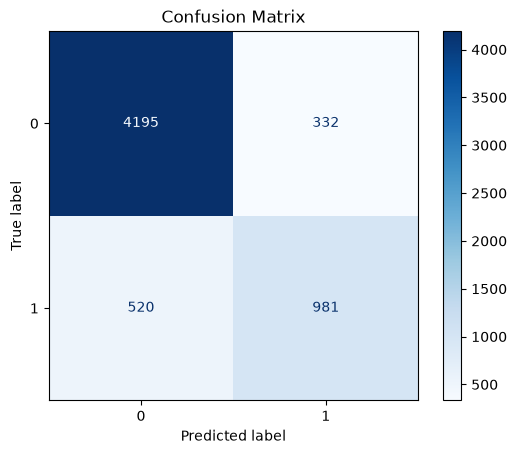

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



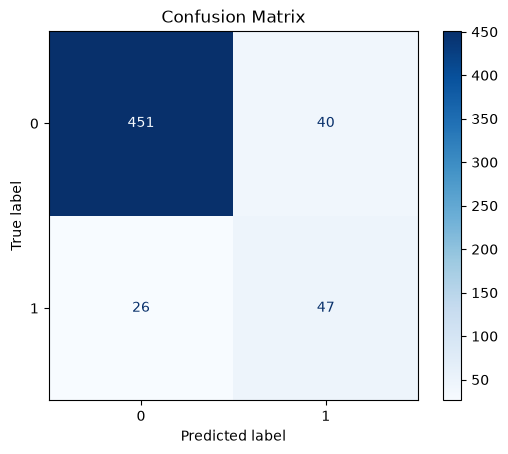

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      4527
           1       0.63      0.64      0.64      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.76      0.76      6028
weighted avg       0.82      0.82      0.82      6028



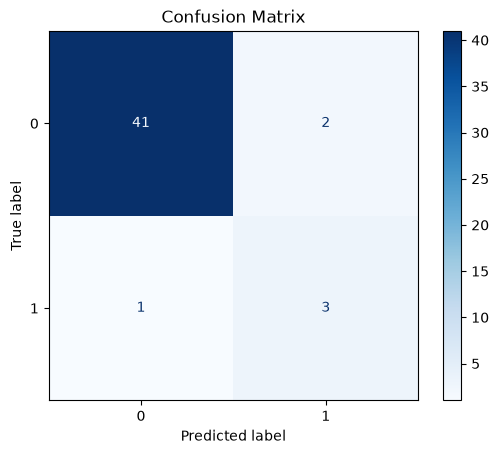

In [107]:
bagging_clf = BaggingClassifier(estimator=stacking_clf, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)